11/25/2026 Gottlieb

**Guiding Question**: How large must a known mean return (planted drift) be before the V&F detector flags it at a false positive rate of 5% on zero-drift simulations?

Here, we are using statistical power to mean the fraction of independent simulated paths falgged when drift is present. Standard convention considers a rate of 80% power to be reliable.

### 1. Create market generator

For our simulations we consider the case of two risky assets and cash. At each step, both risky assets get the same random shock $b_t$ and separate noise $e_{1t}$ and $e_{2t}$. We plant a mean $\delta$ in opposite directions:
$$r_{1t} = b_t + e_{1t} + \delta/\sqrt2, \qquad r_{2t} = b_t + e_{2t} - \delta/\sqrt2$$

The shocks are independent over time, with standard deviations $c$ for the common noise and $s$ for each asset's individual noise. The calm direction $J^* = (0,1,-1)/\sqrt{2}$ therefore has a per-step mean of $\delta$ and standard deviation $s$.

The following functions `simulate(p, T, seed)` returns the log-return columns for the two risky assets, and `truth(p)` returns the exact risky-asset mean $\mu$ and covariances $G_0$ and $G_1$ (see the simulation phase overview document)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from src.gauge_arbitrage.vf import detector, predict

In [2]:
def simulate(p, T, seed):
    """Two risky log-return columns, shape (T, 2)."""
    rng = np.random.default_rng(seed)
    b = rng.normal(0, p["common_sd"], T)
    e = rng.normal(0, p["indep_sd"], (T, 2))
    return b[:, None] + e + p["delta"]*np.array([1, -1])/np.sqrt(2)


def truth(p):
    """Exact (mu, G0, G1) for the two risky assets."""
    c, s, delta = p["common_sd"], p["indep_sd"], p["delta"]
    mu = delta*np.array([1, -1])/np.sqrt(2)
    G0 = c**2*np.ones((2, 2)) + s**2*np.eye(2)
    G1 = np.zeros((2, 2))
    return mu, G0, G1

### 2. Check the known answer

For fixed $J^*$ we expect the product of consecutive returns to be $D_{pred} = \delta^2$ because there is no lag-1 covariance. The actual detector estimates and updates its direction from data, so this is just an estimate of what the result should be.

The method `predict.predict(G0, G1)` identifies a samples calm direction. It returns weights in the order (asset 1, asset 2, cash), therefore we will reorder them to arrange cash to the beginning.

In [3]:
seed = 20261125 # experiment seed

c = 1.0         # common noise standard deviation
s = 0.5         # independent noise standard deviation
delta = 0.1     # planted drift
def params(delta, c, s): return dict(delta=delta, common_sd=c, indep_sd=s)
p = params(delta, c, s)

mu, G0, G1 = truth(p)
pred = predict.predict(G0, G1)

J_star = pred["J"][[2, 0, 1]]                       # calm direction rearranged to cash-first order
D_pred = pred["D_pred"] + (pred["J"][:2] @ mu)**2   # predicted detector value

print("J*:", J_star)
print("Predicted detector value:", D_pred)

J*: [ 0.          0.70710678 -0.70710678]
Predicted detector value: 0.009999999999999998


### 3. Define a score for a detector result

The method `detector.run_detector` implements the V&F detector by using the previous $L$ returns to select a zero-cost, low-variance portfolio, and to then multiply it with the next return. Every refresh this portfolio is updated. The method returns a dictionary of information, but what we care about is `products`. We will take the mean of $S$ products to find the estimated detector value. This is our score.

In [4]:
L = 250         # estimation window
S = 1000        # scored products to take
refresh = 5     # refresh rate for rolling estimation

def score(R):
    # compute detector value for a single path of R returns
    res = detector.run_detector(R, L=L, refresh=refresh, n_dirs=1, use_cash=True, dt=1.0)
    products = res["products"][L+1:]
    return products.mean()

R = simulate(p, L+S+1, seed)
print("Detector score:", score(R))

Detector score: 0.008597186063525053


### 4. Set a 5% false-positive cutoff rate

The null market has a drift of $\delta = 0$. We will generate many independent null paths and calculate a detector score for each. The 95th percentile will be our cutoff such that scores above it are flagged. We will then use a different set of null paths to check the observed false-positive rate. A rate near 5% of paths flagged means the calibration is behaving as intended.

In [5]:
n_paths = 300   # independent paths to simulate per drift

# delta / s
ratios = np.array([0, .05, .10, .15, .20, .25, .30, .35, .40])

# use separate random seeds for each null and drift setting
seed_groups = np.random.SeedSequence(seed).spawn(len(ratios)+1)
seed_sets = [np.array([int(x.generate_state(1)[0]) for x in g.spawn(n_paths)]) for g in seed_groups]

def run_paths(p, seeds):
    return np.array([score(simulate(p, L+S+1, int(s))) for s in seeds])

# calibrate the 5% cutoff using zero-drift paths
p_0 = params(0, c, s)
null_cal = run_paths(p_0, seed_sets[0])
cutoff = float(np.quantile(null_cal, .95))

# check the cutoff on new zero-drift paths
null_check = run_paths(p_0, seed_sets[1])
false_positive_rate = np.mean(null_check > cutoff)

print(f"Score cutoff: {cutoff:.5f}")
print(f"Flag rate: {np.sum(null_check > cutoff)}/{n_paths} = {false_positive_rate:.1%}")

Score cutoff: 0.01325
Flag rate: 9/300 = 3.0%


### 5. Measure power at various drifts

At each positive $\delta$ being tested we will make paths with the same noise settings used in the null calibrations, and then apply the cutoff margin. The fraction flagged is the estimated power at that particular drit. 80% power will be the threshold for reliable flags. This is the answer to the question posed at the beginning of the notebook.

In [6]:
scores = {0.0: null_check}
# apply the cutoff to new paths at each planted drift
for ratio, seeds in zip(ratios[1:], seed_sets[2:]):
    scores[float(ratio)] = run_paths(params(ratio*s, c, s), seeds)

# power is the fraction of paths whose score exceeds the cutoff
counts = np.array([np.sum(scores[float(x)] > cutoff) for x in ratios])
power = counts/n_paths

print("delta/s   flagged/paths   estimated power")
for ratio, count, rate in zip(ratios, counts, power):
    print(f" {ratio:4.2f}      {count:3d}/{n_paths}         {rate:5.1%}")

delta/s   flagged/paths   estimated power
 0.00        9/300          3.0%
 0.05        9/300          3.0%
 0.10       27/300          9.0%
 0.15       69/300         23.0%
 0.20      101/300         33.7%
 0.25      184/300         61.3%
 0.30      248/300         82.7%
 0.35      293/300         97.7%
 0.40      300/300         100.0%


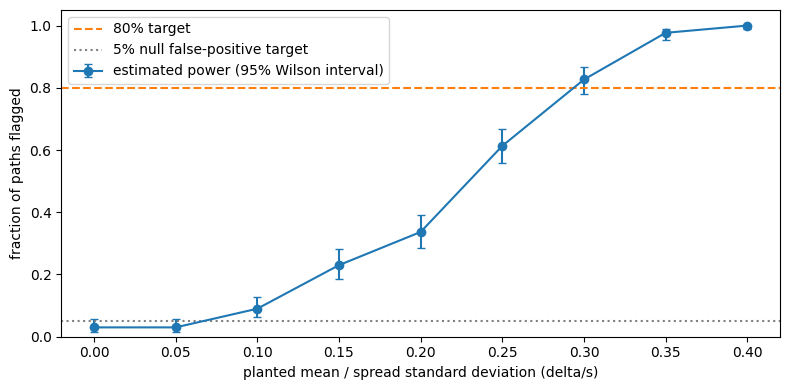

In [7]:
# quantify uncertainty using Wilson interval
def wilson_interval(p_hat, n, z=1.96):
    center = (p_hat + z*z/(2*n)) / (1 + z*z/n)
    half = z * np.sqrt(p_hat * (1-p_hat)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return center-half, center+half

lower, upper = wilson_interval(power, n_paths)

# plot power against drift measured
fig, ax = plt.subplots(figsize=(8, 4))

ax.errorbar(ratios, power, yerr=[np.maximum(0, power-lower), np.maximum(0, upper-power)],
             marker="o", capsize=3, label="estimated power (95% Wilson interval)")
ax.axhline(.80, color="tab:orange", linestyle="--", label="80% target")
ax.axhline(.05, color="gray", linestyle=":", label="5% null false-positive target")

ax.set_xlabel("planted mean / spread standard deviation (delta/s)")
ax.set_ylabel("fraction of paths flagged")
ax.set_ylim(0, 1.05)

ax.legend()
fig.tight_layout()

### 6. Closing remarks

This answer we have found is specific to the simulation setting we have chosen. That is, $L=250$, $S=1000$, with a refresh every five steps, and a selected 80% reliability target. To make the answer more precise we could have increased `n_paths` and rerun the calibration step. Further, a different sample length or noise level would affect the result. These are all tests we can do in future notebooks to get a more complete picture.